# Structural Analysis Toolkit (SAT)

## If anything goes wrong:  
### Restart the kernel using the &#8635; button at the top of this notebook, or from the menu: `Kernel > Restart Kernel...`

## **During the tutorials just run through the cells using the given example files and code. Later you will use your own CAD drawing and edit the code to solve your own structural optimisation problem.**

### Flowchart for this Notebook:

![](flow_1.png)

## Loading the external files

### 0. Open the `truss1.dxf` file in AutoCAD and take a look at it.
### 1. Run the cell below which loads it into Python and creates lists of `Node` and `Member` objects.

In [1]:
# ===================================================
# Ensure the input filenames below match uploded files
# ===================================================
from import_functions import extract_structure_from_dxf

# input files
INPUT_DXF = "truss1.dxf"

# import data and create lists of nodes and members, each with its own ID, name, properties, etc...
nodes, members = extract_structure_from_dxf(INPUT_DXF, units='mm', tol=0.1)

* For info on the `extract_structure_from_dxf` function, run the cell below:

In [2]:
help(extract_structure_from_dxf)

Help on function extract_structure_from_dxf in module import_functions:

extract_structure_from_dxf(file_path, units='mm', tol=0.001)
    Import a DXF line drawing and convert it into a structural model.
    
    The function:
    1. Reads LINE entities from the DXF.
    2. Finds all line intersections.
    3. Creates nodes at endpoints and intersections.
    4. Merges nearby nodes within a tolerance.
    5. Splits members wherever a node lies along a line.
    6. Creates Node and Member objects.
    7. Builds nodal connectivity information.
    
    Parameters
    ----------
    file_path : str
        Path to the DXF file.
    
    units : str
        Either 'mm' or 'm'. If 'mm', coordinates are converted to metres.
    
    tol : float
        Distance tolerance used for node merging and geometric matching.
    
    Returns
    -------
    nodes : dict
        Dictionary of Node objects indexed by node label.
    
    members : dict
        Dictionary of Member objects indexed by me

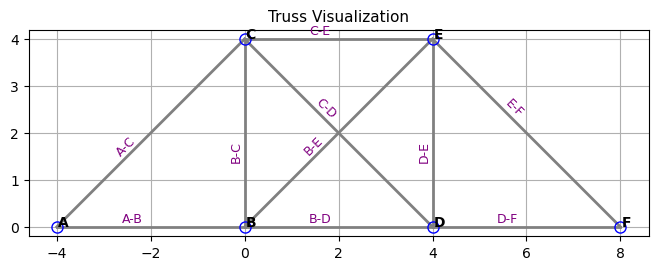

In [3]:
##########################################
# Visualisation of the imported structure
##########################################
from visualisation import visualize_truss

# show the imported structure
fig,ax = visualize_truss(nodes, members, textscale=1, show_node_labels=True, show_member_labels=True)

#### &bullet; **Make sure all of the members and joints have unique labels,**
#####      $-$ if not you need to edit your CAD drawing to make it more accurate.

* We can inspect the nodes (and members) created:

In [4]:
# list the nodes
print(nodes)

{'A': <structural_classes.Node object at 0x7f16fb8cb0d0>, 'B': <structural_classes.Node object at 0x7f16fb8cb110>, 'C': <structural_classes.Node object at 0x7f16fb8cb150>, 'D': <structural_classes.Node object at 0x7f16fb8cb190>, 'E': <structural_classes.Node object at 0x7f16fb8cb1d0>, 'F': <structural_classes.Node object at 0x7f16fb8cb210>}


This is a dictionary with each of the nodes listed, lets look at one:
* click immediately after `.` and press the tab key to view attributes (properties) of the node object
* click on any of them (or type it) to view that property
e.g.:
```python
node.F_x
```

In [5]:
for m in members.values():
    print(m.name)

B-D
D-E
C-E
B-C
A-B
A-C
D-F
E-F
B-E
C-D


In [6]:
for n in nodes.values():
    print(n.label, n.coords, n.connectivity)

A (-4.0, 0.0, 0.0) ['B', 'C']
B (0.0, 0.0, 0.0) ['D', 'C', 'A', 'E']
C (0.0, 4.0, 0.0) ['E', 'B', 'A', 'D']
D (4.0, 0.0, 0.0) ['B', 'E', 'F', 'C']
E (4.0, 4.0, 0.0) ['D', 'C', 'F', 'B']
F (8.0, 0.0, 0.0) ['D', 'E']


In [7]:
help(n)

Help on Node in module structural_classes object:

class Node(builtins.object)
 |  Node(id, coords, label=None, condition='Pinned')
 |  
 |  Structural node with coordinates, loads, reactions and support condition.
 |  
 |  Methods defined here:
 |  
 |  __init__(self, id, coords, label=None, condition='Pinned')
 |      Initialize self.  See help(type(self)) for accurate signature.
 |  
 |  unknowns(self)
 |  
 |  ----------------------------------------------------------------------
 |  Data descriptors defined here:
 |  
 |  __dict__
 |      dictionary for instance variables
 |  
 |  __weakref__
 |      list of weak references to the object



### 2. Edit the dictionary in the cell below then run it to assign different joint types:

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Truss Visualization'}>)

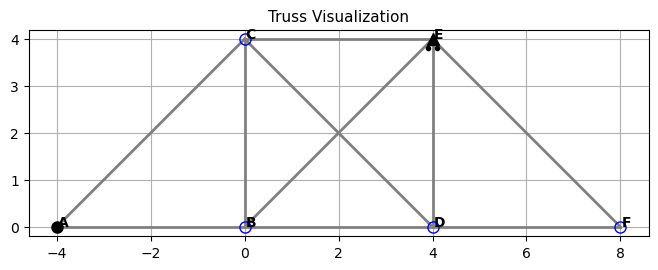

In [8]:
##########################################
# Edit this to assign conditions to joints
##########################################

# comma-separated lists of node-labels as dictionary values 
# default value is "Pinned"
JOINT_CONDITIONS = {
"Pinned":            [],	     # Internal pin (free rotation, no support)	    ○	Blue
"Fixed":             [],         # Internal fixed joint (rigid)	                □	~Blue
"Reaction_Fixed":    [],	     # External fixed support	                    ■	Black
"Reaction_Pinned":   ['A'],      # External pinned support	                    ●	Black
"Reaction_Roller_H": ['E'],      # Horizontal roller (restrained vertically)	▲	Black
"Reaction_Roller_V": []	         # Vertical roller (restrained horizontally)	▼	Black
}

#########################
# Assign point conditions 
#########################
from struct_prop_funcs import apply_joint_conditions

# assign joint conditions
apply_joint_conditions(nodes, JOINT_CONDITIONS)

visualize_truss(nodes, members, show_node_labels=True)

| Type                | Description                               | Marker | Colour |
| ------------------- | ----------------------------------------- | ------ | ----- |
| `Pinned`            | Internal pin (free rotation, no support)  | ○      | Blue  |
| `Fixed`             | Internal fixed joint (rigid)              | □      | Blue  |
| `Reaction_Fixed`    | External fixed support                    | ■      | Black |
| `Reaction_Pinned`   | External pinned support                   | ●      | Black |
| `Reaction_Roller_H` | Horizontal roller (restrained vertically) | ▲      | Black |
| `Reaction_Roller_V` | Vertical roller (restrained horizontally) | ▼      | Black |


## Next follows some examples of what you can do with your structural objects...

### 5. Check if Determinate

#### 2D truss diagnostics with automatic connectivity and total unknown reaction check.

![](determin_flow.png)

Prints a detailed report including:
- Determinacy check
- Support reaction analysis
- Potential mechanism nodes
- Total unknown reaction check
-
**Task:** Study the code below and identify which processes relate to which steps in the flow chart.
* Add comments to explain the purpose of different lines of the code in relation to the task.
```python
# this is a comment, it is for your information and ignored by python when the programme runs
```

In [11]:
n_nodes = len(nodes)
n_members = len(members)
n_reactions = sum(n.unknowns for n in nodes.values())
determinacy = 2 * n_nodes - (n_members + n_reactions)

print("\n### Truss Diagnostics ###")
print(f"Number of nodes (joints):       {n_nodes}")
print(f"Number of members:             {n_members}")
print(f"Number of unknown reactions:   {n_reactions}")
print(f"Determinant (2j - (m+r)):     {determinacy}")

if determinacy == 0:
    status = "=> Statically determinate (truss)"
elif determinacy > 0:
    status = "!!! Unstable mechanism possible (truss)"
else:
    status = "!!! Statically indeterminate (truss)"
print(f"Status: {status}\n")

print("Supports and unknown reaction components:")
problem_supports = []
for label, n in nodes.items():
    cond = n.condition
    if n.unknowns > 0:
        unknowns = n.unknowns
        print(f"  Node {label:>3}: {cond:20} -> {unknowns} unknown reaction(s)")
        if unknowns > 2:
            problem_supports.append((label, cond, "Too many unknown reactions → may cause indeterminacy"))

if problem_supports:
    print("\nProblematic Supports:")
    for label, cond, issue in problem_supports:
        print(f"  Node {label:>3}: {cond:20} -> {issue}")
else:
    print("\nNo problematic supports detected.")

print("\nTotal unknown reaction check:")
if n_reactions > 3:
    print(f"!!! Total unknown reactions = {n_reactions} > 3 --> system is statically indeterminate for rigid 2D body")
elif n_reactions < 3:
    print(f"!!! Total unknown reactions = {n_reactions} < 3 --> system may be unstable (mechanism possible)")
else:
    print(f"=> Total unknown reactions = {n_reactions} --> externally determinate")

potential_mech_nodes = []
for label, n in nodes.items():
    if n.unknowns == 0 and len(n.connectivity) < 2:
        print(f"Warning: Node {label} has {len(n.connectivity)} connected member(s)")
    cond = n.condition
    if n.unknowns > 0:
        continue  
    n_conn = len(n.connectivity) 
    if n_conn < 2:
        potential_mech_nodes.append((label, n_conn, "Too few connected members --> possible local mechanism"))

if potential_mech_nodes:
    print("\nPotential Mechanism Nodes:")
    for label, n_conn, issue in potential_mech_nodes:
        print(f"  Node {label}: {n_conn} member(s) connected -> {issue}")
else:
    print("\nNo obvious local mechanism nodes detected.")



### Truss Diagnostics ###
Number of nodes (joints):       6
Number of members:             10
Number of unknown reactions:   3
Determinant (2j - (m+r)):     -1
Status: !!! Statically indeterminate (truss)

Supports and unknown reaction components:
  Node   A: Reaction_Pinned      -> 2 unknown reaction(s)
  Node   E: Reaction_Roller_H    -> 1 unknown reaction(s)

No problematic supports detected.

Total unknown reaction check:
=> Total unknown reactions = 3 --> externally determinate

No obvious local mechanism nodes detected.


You could edit the structure in AutoCAD and remove a member to make it determinate.

However, the following cell shows how to define a new function for removing a node automatically:

In [12]:
def remove_member(nodes, members, member_name):
    # remove the member from the dictionary of members
    m = members.pop(member_name)

    # get the node labels for the start and end of the deleted member
    n1 = m.start_node.label
    n2 = m.end_node.label

    # update node connectivity
    nodes[n1].connectivity.remove(n2)
    nodes[n2].connectivity.remove(n1)

* remind yourself how to define functions using parameters and the `def` keyword.

The next cell shows using the new function and visualising:

In [14]:
remove_member(nodes, members, "C-D")
fig,ax = visualize_truss(nodes, members, textscale=1, show_node_labels=True, show_member_labels=True)

KeyError: 'C-D'

Task: define a new function called `check_determinacy` and put the entire determinacy checking code into a function code block so it can be re-used as a function:

In [ ]:
# define a function name here
    # the code for the
    # determinacy check
    # all goes here

* now run the cell below to call your function on the updated nodes and members:

In [ ]:
check_determinacy(nodes, members)

## Finally: Save your new structure back to a DXF to import into AutoCAD

In [ ]:
from import_functions import export_to_dxf

OUTPUT_DXF = "edited_structure.dxf"

# save new structure
export_to_dxf(nodes, members, OUTPUT_DXF, units='mm')